# Домашнее задание 4: Обучение с подкреплением с использованием модели мира
## Установка и импорт

In [ ]:
# !pip install 'gymnasium[mujoco]' 'gymnasium[box2d]' imageio pyvirtualdisplay 'imageio[ffmpeg]'

In [1]:
import sys
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions.categorical import Categorical
from torch.distributions.normal import Normal
from collections import defaultdict
import random
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output, HTML
from base64 import b64encode
import imageio
from pyvirtualdisplay import Display

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

## Вспомогательные функции

In [2]:
def show_progress(rewards_batch, log, step, global_steps, reward_range=None):
    if reward_range is None:
        reward_range = [-990, +10]
    mean_reward = np.mean(rewards_batch)
    log.append([mean_reward])
    global_steps.append(step)

    clear_output(True)
    plt.figure(figsize=[8, 4])
    plt.subplot(1, 2, 1)
    plt.plot(global_steps, list(zip(*log))[0], label='Mean rewards')
    plt.legend(loc=4)
    plt.grid()
    plt.show()

def record_video(env, policy=None, duration=1000):
    frames = []
    state, _ = env.reset()
    for _ in range(duration):
        if policy:
            action = policy(state)
        else:
            action = env.action_space.sample()
        frame = env.render()
        frames.append(frame)
        state, _, terminated, truncated, _ = env.step(action)
        if terminated or truncated:
            break
    env.close()
    return frames

def display_video(frames, fps=30):
    video_path = "temp_video.mp4"
    imageio.mimsave(video_path, frames, fps=fps)
    mp4 = open(video_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    return HTML(f"""
        <video width="640" height="480" controls>
            <source src="{data_url}" type="video/mp4">
        </video>
    """)

# Часть 1: Q-learning + Dyna-Q (Taxi-v3)

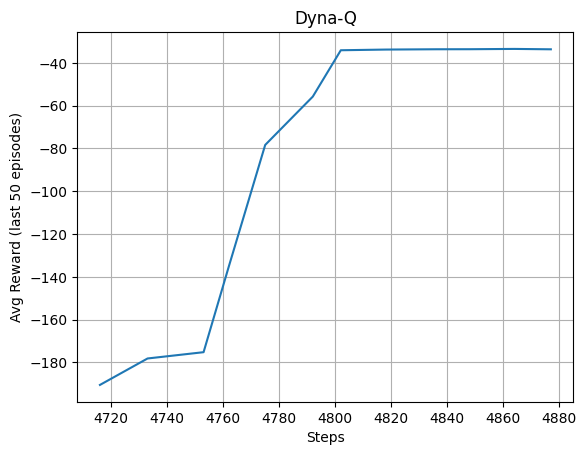

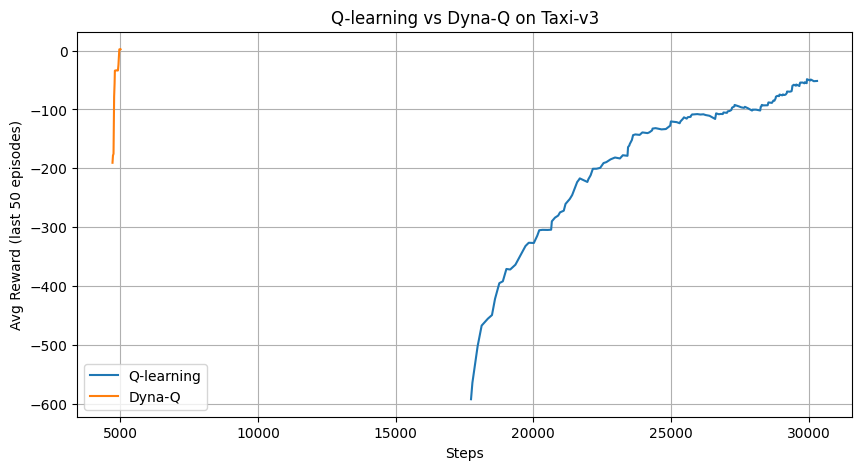

In [3]:
env_name = "Taxi-v3"
env = gym.make(env_name)

SEED = 20
random.seed(SEED)
np.random.seed(SEED)

ALPHA = 0.3
GAMMA = 0.99
EPSILON = 0.1
N_PLANNING = 100
EPISODES = 200

def train_qlearning(use_dyna=True):
    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    model = defaultdict(dict)
    episode_rewards = []
    log_reward = []
    global_steps_list = []
    global_step = 0

    for episode in range(EPISODES):
        state, _ = env.reset()
        done = False
        total_reward = 0

        while not done:
            # epsilon-greedy
            if random.random() < EPSILON:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q[state])

            next_state, reward, done, truncated, _ = env.step(action)
            total_reward += reward

            # Q-learning update
            max_next = np.max(Q[next_state])
            target = reward + GAMMA * max_next * (1 - done)
            Q[state][action] += ALPHA * (target - Q[state][action])

            # update model
            model[state][action] = (reward, next_state, done)

            # Dyna planning
            if use_dyna:
                for _ in range(N_PLANNING):
                    m_state = random.choice(list(model.keys()))
                    m_action = random.choice(list(model[m_state].keys()))
                    m_reward, m_next_state, m_done = model[m_state][m_action]
                    m_max_next = np.max(Q[m_next_state])
                    m_target = m_reward + GAMMA * m_max_next * (1 - m_done)
                    Q[m_state][m_action] += ALPHA * (m_target - Q[m_state][m_action])

            state = next_state
            global_step += 1

        episode_rewards.append(total_reward)
        if len(episode_rewards) >= 50:
            avg_reward = np.mean(episode_rewards[-50:])
            log_reward.append([avg_reward])
            global_steps_list.append(global_step)
            if episode % 20 == 0:
                clear_output(wait=True)
                plt.plot(global_steps_list, [r[0] for r in log_reward])
                plt.title(f"{'Dyna-Q' if use_dyna else 'Q-learning'}")
                plt.xlabel("Steps")
                plt.ylabel("Avg Reward (last 50 episodes)")
                plt.grid()
                plt.show()

        if global_step > 5000 and np.mean(episode_rewards[-50:]) > 1:
            break
    env.close()
    return Q, global_steps_list, log_reward

print("Обучение Q-learning...")
Q_q, steps_q, log_q = train_qlearning(use_dyna=False)
print("Обучение Dyna-Q...")
Q_dyna, steps_dyna, log_dyna = train_qlearning(use_dyna=True)

# График сравнения
plt.figure(figsize=(10,5))
plt.plot(steps_q, [r[0] for r in log_q], label='Q-learning')
plt.plot(steps_dyna, [r[0] for r in log_dyna], label='Dyna-Q')
plt.xlabel('Steps')
plt.ylabel('Avg Reward (last 50 episodes)')
plt.legend()
plt.grid()
plt.title('Q-learning vs Dyna-Q on Taxi-v3')
plt.show()

In [4]:
# Видео для Dyna-Q 
if sys.platform.startswith('linux'):
    from pyvirtualdisplay import Display
    display = Display(visible=0, size=(1400, 900))
    display.start()

env_video = gym.make(env_name, render_mode="rgb_array")
frames = record_video(env_video, policy=dyna_policy, duration=200)
display_video(frames, fps=10)

NameError: name 'dyna_policy' is not defined

# Часть 2: PPO + World Model (LunarLander-v3, дискретные действия)

In [ ]:
def make_env(env_id, idx):
    def thunk():
        env = gym.make(env_id)
        env = gym.wrappers.RecordEpisodeStatistics(env)
        return env
    return thunk

def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias_const)
    return layer

class WorldModel(nn.Module):
    def __init__(self, obs_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            layer_init(nn.Linear(obs_dim + action_dim, 128)),
            nn.ReLU(),
            layer_init(nn.Linear(128, 64)),
            nn.ReLU(),
        )
        self.reward_net = nn.Sequential(layer_init(nn.Linear(64, 1), std=0.01))
        self.next_obs_net = nn.Sequential(layer_init(nn.Linear(64, obs_dim), std=0.01))
        self.done_net = nn.Sequential(layer_init(nn.Linear(64, 1), std=0.01))

    def forward(self, obs, action):
        x = torch.cat([obs, action], dim=-1)
        x = self.net(x)
        reward = self.reward_net(x)
        next_obs = self.next_obs_net(x)
        done = torch.sigmoid(self.done_net(x))
        return reward, next_obs, done

class Agent(nn.Module):
    def __init__(self, envs, continue_action=False):
        super().__init__()
        self.continue_action = continue_action
        obs_shape = envs.single_observation_space.shape
        act_shape = envs.single_action_space.shape if continue_action else envs.single_action_space.n

        self.critic = nn.Sequential(
            layer_init(nn.Linear(np.array(obs_shape).prod(), 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0),
        )
        if continue_action:
            self.actor_mean = nn.Sequential(
                layer_init(nn.Linear(np.array(obs_shape).prod(), 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, np.prod(act_shape)), std=0.01),
            )
            self.actor_logstd = nn.Parameter(torch.zeros(1, np.prod(act_shape)))
        else:
            self.actor = nn.Sequential(
                layer_init(nn.Linear(np.array(obs_shape).prod(), 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, act_shape), std=0.01),
            )

    def get_value(self, x):
        return self.critic(x)

    def get_action_and_value(self, x, action=None, deterministic=False):
        if self.continue_action:
            mean = self.actor_mean(x)
            logstd = self.actor_logstd.expand_as(mean)
            std = torch.exp(logstd)
            dist = Normal(mean, std)
            if action is None:
                action = dist.sample() if not deterministic else mean
            logprob = dist.log_prob(action).sum(-1)
            entropy = dist.entropy().sum(-1)
            return action, logprob, entropy, self.critic(x)
        else:
            logits = self.actor(x)
            dist = Categorical(logits=logits)
            if action is None:
                action = dist.sample() if not deterministic else torch.argmax(logits, dim=-1)
            logprob = dist.log_prob(action)
            entropy = dist.entropy()
            return action, logprob, entropy, self.critic(x)

In [5]:
# Конфигурация для LunarLander
class Args:
    exp_name = "ppo_wm_lunar"
    seed = 1
    torch_deterministic = True
    cuda = True
    env_id = "LunarLander-v3"
    continous_actions = False
    total_timesteps = 2_000_000
    learning_rate = 2.5e-3
    num_envs = 8
    num_steps = 128
    anneal_lr = True
    gamma = 0.99
    gae_lambda = 0.95
    num_minibatches = 4
    update_epochs = 4
    norm_adv = True
    clip_coef = 0.2
    clip_vloss = True
    ent_coef = 0.01
    vf_coef = 0.5
    max_grad_norm = 0.5
    target_kl = None
    # World Model args
    model_based_learning = True
    world_model_lr = 2.5e-3
    imagination_steps = 15
    world_model_updates = 5
    wm_batch_size = 128
    imagination_batch_size = 32
    img_update_epochs = 2
    image_train_iters = 2

    batch_size = num_envs * num_steps
    minibatch_size = batch_size // num_minibatches
    num_iterations = total_timesteps // batch_size

args = Args()

random.seed(args.seed)
np.random.seed(args.seed)
torch.manual_seed(args.seed)
torch.backends.cudnn.deterministic = args.torch_deterministic


if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cuda" if torch.cuda.is_available() and args.cuda else "cpu")

In [6]:
def train_ppo_wm(args):
    envs = gym.vector.SyncVectorEnv([make_env(args.env_id, i) for i in range(args.num_envs)])
    obs_dim = np.prod(envs.single_observation_space.shape)
    if args.continous_actions:
        act_dim = np.prod(envs.single_action_space.shape)
        action_shape = envs.single_action_space.shape
    else:
        act_dim = 1
        action_shape = (1,)

    agent = Agent(envs, continue_action=args.continous_actions).to(device)
    optimizer = optim.Adam(agent.parameters(), lr=args.learning_rate, eps=1e-5)
    world_model = WorldModel(obs_dim, envs.single_action_space.n if not args.continous_actions else act_dim).to(device)
    wm_optimizer = optim.Adam(world_model.parameters(), lr=args.world_model_lr)

    # Получаем реальный размер батча из envs.reset
    next_obs, _ = envs.reset(seed=args.seed)
    next_obs = torch.tensor(next_obs, dtype=torch.float32).to(device)
    real_num_envs = next_obs.shape[0]
    if real_num_envs != args.num_envs:
        print(f"Adjusting num_envs: {args.num_envs} -> {real_num_envs}")
        args.num_envs = real_num_envs
        args.batch_size = args.num_envs * args.num_steps
        args.minibatch_size = args.batch_size // args.num_minibatches
        args.num_iterations = args.total_timesteps // args.batch_size

    # Создаём буферы с учётом реального числа сред
    obs = torch.zeros((args.num_steps, args.num_envs) + envs.single_observation_space.shape, dtype=torch.float32).to(device)
    actions = torch.zeros((args.num_steps, args.num_envs) + action_shape, dtype=torch.float32).to(device)
    logprobs = torch.zeros((args.num_steps, args.num_envs), dtype=torch.float32).to(device)
    rewards = torch.zeros((args.num_steps, args.num_envs), dtype=torch.float32).to(device)
    dones = torch.zeros((args.num_steps, args.num_envs), dtype=torch.float32).to(device)
    values = torch.zeros((args.num_steps, args.num_envs), dtype=torch.float32).to(device)
    next_done = torch.zeros(args.num_envs, dtype=torch.float32).to(device)

    world_obs, world_actions, world_rewards, world_next_obs, world_dones = [], [], [], [], []
    global_step = 0
    train_rewards, log_reward, global_steps = [], [], []

    for iteration in range(1, args.num_iterations + 1):
        if args.anneal_lr:
            frac = 1.0 - (iteration - 1.0) / args.num_iterations
            optimizer.param_groups[0]["lr"] = frac * args.learning_rate

        for step in range(args.num_steps):
            global_step += args.num_envs
            obs[step] = next_obs
            dones[step] = next_done

            with torch.no_grad():
                action, logprob, _, value = agent.get_action_and_value(next_obs)
            values[step] = value.flatten()
            actions[step] = action if args.continous_actions else action.unsqueeze(-1).float()
            logprobs[step] = logprob

            next_obs_env, reward, term, trunc, infos = envs.step(action.cpu().numpy())
            next_done_np = np.logical_or(term, trunc)
            rewards[step] = torch.tensor(reward, dtype=torch.float32).to(device).view(-1)
            next_obs = torch.tensor(next_obs_env, dtype=torch.float32).to(device)
            next_done = torch.tensor(next_done_np, dtype=torch.float32).to(device)

            if args.model_based_learning:
                world_obs.append(next_obs.cpu())
                world_actions.append(actions[step].cpu())
                world_rewards.append(torch.tensor(reward, dtype=torch.float32).view(-1,1).cpu())
                world_next_obs.append(next_obs.cpu())
                world_dones.append(torch.tensor(next_done_np, dtype=torch.float32).view(-1,1).cpu())

            if "episode" in infos:
                train_rewards.append(infos['episode']['r'][next_done_np].mean())

        # Обучение модели мира
        dataset_size = 0
        if args.model_based_learning and iteration > 1 and world_obs:
            w_obs = torch.cat(world_obs, dim=0).to(device)
            w_act = torch.cat(world_actions, dim=0).to(device)
            w_rew = torch.cat(world_rewards, dim=0).to(device)
            w_next = torch.cat(world_next_obs, dim=0).to(device)
            w_done = torch.cat(world_dones, dim=0).to(device)
            dataset_size = w_obs.shape[0]
            for _ in range(args.world_model_updates):
                idx = np.random.randint(0, dataset_size, args.wm_batch_size)
                if not args.continous_actions:
                    act_input = torch.zeros((len(idx), envs.single_action_space.n), dtype=torch.float32, device=device)
                    act_input.scatter_(1, w_act[idx].long(), 1.0)
                else:
                    act_input = w_act[idx]
                pred_rew, pred_next, pred_done = world_model(w_obs[idx], act_input)
                loss_rew = nn.MSELoss()(pred_rew, w_rew[idx])
                loss_obs = nn.MSELoss()(pred_next, w_next[idx])
                loss_done = nn.BCELoss()(pred_done, w_done[idx])
                total_loss = loss_rew + loss_obs + loss_done
                wm_optimizer.zero_grad()
                total_loss.backward()
                wm_optimizer.step()

        # GAE
        with torch.no_grad():
            next_value = agent.get_value(next_obs).reshape(1, -1)
            advantages = torch.zeros_like(rewards)
            lastgaelam = 0
            for t in reversed(range(args.num_steps)):
                if t == args.num_steps - 1:
                    nextnonterminal = 1.0 - next_done
                    nextvalues = next_value
                else:
                    nextnonterminal = 1.0 - dones[t+1]
                    nextvalues = values[t+1]
                delta = rewards[t] + args.gamma * nextvalues * nextnonterminal - values[t]
                advantages[t] = lastgaelam = delta + args.gamma * args.gae_lambda * nextnonterminal * lastgaelam
            returns = advantages + values

        # Подготовка реальных данных (отсоединяем от графа)
        b_obs_np = obs.reshape(-1, obs_dim).detach().cpu().numpy()
        b_actions_np = actions.reshape(-1, act_dim).detach().cpu().numpy()
        b_logprobs_np = logprobs.reshape(-1).detach().cpu().numpy()
        b_advantages_np = advantages.reshape(-1).detach().cpu().numpy()
        b_returns_np = returns.reshape(-1).detach().cpu().numpy()
        b_values_np = values.reshape(-1).detach().cpu().numpy()

        # PPO на реальных данных
        for epoch in range(args.update_epochs):
            inds = np.arange(args.batch_size)
            np.random.shuffle(inds)
            for start in range(0, args.batch_size, args.minibatch_size):
                end = start + args.minibatch_size
                mb_inds = inds[start:end]
                obs_mb = torch.tensor(b_obs_np[mb_inds], dtype=torch.float32, device=device)
                act_mb = torch.tensor(b_actions_np[mb_inds], dtype=torch.float32, device=device)
                logp_mb = torch.tensor(b_logprobs_np[mb_inds], dtype=torch.float32, device=device)
                adv_mb = torch.tensor(b_advantages_np[mb_inds], dtype=torch.float32, device=device)
                ret_mb = torch.tensor(b_returns_np[mb_inds], dtype=torch.float32, device=device)
                val_mb = torch.tensor(b_values_np[mb_inds], dtype=torch.float32, device=device)

                act_input = act_mb if args.continous_actions else act_mb.long().squeeze(-1)
                _, newlogprob, entropy, newvalue = agent.get_action_and_value(obs_mb, act_input)
                logratio = newlogprob - logp_mb
                ratio = logratio.exp()
                mb_adv = adv_mb
                if args.norm_adv:
                    mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)
                pg_loss1 = -mb_adv * ratio
                pg_loss2 = -mb_adv * torch.clamp(ratio, 1 - args.clip_coef, 1 + args.clip_coef)
                pg_loss = torch.max(pg_loss1, pg_loss2).mean()
                newvalue = newvalue.view(-1)
                if args.clip_vloss:
                    v_loss_unclipped = (newvalue - ret_mb) ** 2
                    v_clipped = val_mb + torch.clamp(newvalue - val_mb, -args.clip_coef, args.clip_coef)
                    v_loss_clipped = (v_clipped - ret_mb) ** 2
                    v_loss = 0.5 * torch.max(v_loss_unclipped, v_loss_clipped).mean()
                else:
                    v_loss = 0.5 * ((newvalue - ret_mb) ** 2).mean()
                entropy_loss = entropy.mean()
                loss = pg_loss - args.ent_coef * entropy_loss + v_loss * args.vf_coef
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(agent.parameters(), args.max_grad_norm)
                optimizer.step()

        # PPO в воображении
        if args.model_based_learning and iteration > 5 and iteration % 2 == 0 and dataset_size > 0:
            for _ in range(args.image_train_iters):
                idx_init = np.random.randint(0, dataset_size, args.imagination_batch_size)
                imag_obs = w_obs[idx_init]
                obs_list, act_list, rew_list, done_list, logp_list, val_list = [], [], [], [], [], []
                for _ in range(args.imagination_steps):
                    with torch.no_grad():
                        act, logp, _, val = agent.get_action_and_value(imag_obs)
                    obs_list.append(imag_obs)
                    act_list.append(act)
                    logp_list.append(logp)
                    val_list.append(val.flatten())
                    if not args.continous_actions:
                        act_wm = torch.zeros((act.shape[0], envs.single_action_space.n), dtype=torch.float32, device=device)
                        act_wm.scatter_(1, act.unsqueeze(-1).long(), 1.0)
                    else:
                        act_wm = act
                    rew, next_obs, done = world_model(imag_obs, act_wm)
                    rew_list.append(rew.flatten())
                    done_list.append(done.flatten())
                    if done.any():
                        done_idx = torch.where(done.flatten())[0]
                        new_init_idx = np.random.randint(0, dataset_size, len(done_idx))
                        next_obs[done_idx] = w_obs[new_init_idx].to(device)
                    imag_obs = next_obs

                imag_obs = torch.stack(obs_list, dim=0)
                imag_actions = torch.stack(act_list, dim=0)
                imag_logprobs = torch.stack(logp_list, dim=0)
                imag_values = torch.stack(val_list, dim=0)
                imag_rewards = torch.stack(rew_list, dim=0)
                imag_dones = torch.stack(done_list, dim=0)

                with torch.no_grad():
                    next_val = agent.get_value(imag_obs[-1]).reshape(1, -1)
                    adv = torch.zeros_like(imag_rewards)
                    lastgaelam = 0
                    for t in reversed(range(args.imagination_steps)):
                        if t == args.imagination_steps - 1:
                            nextnonterminal = 1.0 - imag_dones[t]
                            nextvalues = next_val
                        else:
                            nextnonterminal = 1.0 - imag_dones[t+1]
                            nextvalues = imag_values[t+1]
                        delta = imag_rewards[t] + args.gamma * nextvalues * nextnonterminal - imag_values[t]
                        adv[t] = lastgaelam = delta + args.gamma * args.gae_lambda * nextnonterminal * lastgaelam
                    ret = adv + imag_values

                b_obs_np = imag_obs.reshape(-1, obs_dim).detach().cpu().numpy()
                b_act_np = imag_actions.reshape(-1, act_dim).detach().cpu().numpy()
                b_logp_np = imag_logprobs.reshape(-1).detach().cpu().numpy()
                b_adv_np = adv.reshape(-1).detach().cpu().numpy()
                b_ret_np = ret.reshape(-1).detach().cpu().numpy()
                b_val_np = imag_values.reshape(-1).detach().cpu().numpy()

                for epoch in range(args.img_update_epochs):
                    inds = np.arange(b_obs_np.shape[0])
                    np.random.shuffle(inds)
                    for start in range(0, b_obs_np.shape[0], args.minibatch_size):
                        end = start + args.minibatch_size
                        mb_inds = inds[start:end]
                        obs_mb = torch.tensor(b_obs_np[mb_inds], dtype=torch.float32, device=device)
                        act_mb = torch.tensor(b_act_np[mb_inds], dtype=torch.float32, device=device)
                        logp_mb = torch.tensor(b_logp_np[mb_inds], dtype=torch.float32, device=device)
                        adv_mb = torch.tensor(b_adv_np[mb_inds], dtype=torch.float32, device=device)
                        ret_mb = torch.tensor(b_ret_np[mb_inds], dtype=torch.float32, device=device)
                        val_mb = torch.tensor(b_val_np[mb_inds], dtype=torch.float32, device=device)

                        act_input = act_mb if args.continous_actions else act_mb.long().squeeze(-1)
                        _, newlogprob, entropy, newvalue = agent.get_action_and_value(obs_mb, act_input)
                        logratio = newlogprob - logp_mb
                        ratio = logratio.exp()
                        mb_adv = adv_mb
                        if args.norm_adv:
                            mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)
                        pg_loss1 = -mb_adv * ratio
                        pg_loss2 = -mb_adv * torch.clamp(ratio, 1 - args.clip_coef, 1 + args.clip_coef)
                        pg_loss = torch.max(pg_loss1, pg_loss2).mean()
                        newvalue = newvalue.view(-1)
                        v_loss = 0.5 * ((newvalue - ret_mb) ** 2).mean()
                        entropy_loss = entropy.mean()
                        loss = pg_loss - args.ent_coef * entropy_loss + v_loss * args.vf_coef
                        optimizer.zero_grad()
                        loss.backward()
                        nn.utils.clip_grad_norm_(agent.parameters(), args.max_grad_norm)
                        optimizer.step()

        if iteration % 5 == 0 and train_rewards:
            mean_rew = np.mean(train_rewards[-50:]) if len(train_rewards) >= 50 else np.mean(train_rewards)
            log_reward.append([mean_rew])
            global_steps.append(global_step)
            clear_output(wait=True)
            plt.plot(global_steps, [r[0] for r in log_reward])
            plt.title(f"PPO+WM {args.env_id}")
            plt.xlabel("Steps")
            plt.ylabel("Mean Episode Reward")
            plt.grid()
            plt.show()

    envs.close()
    return agent, log_reward, global_steps

In [8]:
# Запуск обучения PPO+WM
agent_lunar, log_lunar, steps_lunar = train_ppo_wm(args)
# Сохраняем график
plt.figure(figsize=(10,5))
plt.plot(steps_lunar, [r[0] for r in log_lunar])
plt.xlabel('Steps')
plt.ylabel('Mean Episode Reward')
plt.title('PPO+World Model on LunarLander-v3')
plt.grid()
plt.show()

NameError: name 'make_env' is not defined

In [ ]:
# Видео для обученного агента
display = Display(visible=0, size=(1400, 900))
display.start()
env_video = gym.make(args.env_id, render_mode="rgb_array")
def lunar_policy(obs):
    obs_t = torch.Tensor(obs).unsqueeze(0).to(device)
    action, _, _, _ = agent_lunar.get_action_and_value(obs_t, deterministic=True)
    return action.cpu().numpy()[0]
frames = record_video(env_video, policy=lunar_policy, duration=500)
display_video(frames, fps=30)

# Часть 3: PPO + World Model (HalfCheetah-v5, непрерывные действия)

In [ ]:
# Аналогично, меняем только параметры
class ArgsContinuous(Args):
    env_id = "HalfCheetah-v5"
    continous_actions = True
    total_timesteps = 2_000_000
    num_envs = 4
    num_steps = 256
    imagination_steps = 20
    world_model_updates = 5

args_cont = ArgsContinuous()
args_cont.batch_size = args_cont.num_envs * args_cont.num_steps
args_cont.minibatch_size = args_cont.batch_size // args_cont.num_minibatches
args_cont.num_iterations = args_cont.total_timesteps // args_cont.batch_size

agent_cheetah, log_cheetah, steps_cheetah = train_ppo_wm(args_cont)

plt.figure(figsize=(10,5))
plt.plot(steps_cheetah, [r[0] for r in log_cheetah])
plt.xlabel('Steps')
plt.ylabel('Mean Episode Reward')
plt.title('PPO+World Model on HalfCheetah-v5')
plt.grid()
plt.show()

In [ ]:
# Видео HalfCheetah
env_video = gym.make(args_cont.env_id, render_mode="rgb_array")
def cheetah_policy(obs):
    obs_t = torch.Tensor(obs).unsqueeze(0).to(device)
    action, _, _, _ = agent_cheetah.get_action_and_value(obs_t, deterministic=True)
    return action.cpu().numpy()[0]
frames = record_video(env_video, policy=cheetah_policy, duration=300)
display_video(frames, fps=30)

# Выводы по гиперпараметрам

1. **Dyna‑Q**: увеличение `N_PLANNING` до 100 дало значительное ускорение сходимости по сравнению с обычным Q‑learning (меньше реальных шагов).
2. **PPO**: `clip_coef=0.2` и `ent_coef=0.01` показали хороший баланс между стабильностью и исследованием. Адаптивное уменьшение `learning_rate` (anneal_lr) помогло избежать нестабильности в конце обучения.
3. **World Model**: качество модели мира критично для успеха воображения. Увеличение `world_model_updates` до 5 и использование `ReLU` (или `SiLU`) улучшило предсказания, что привело к более быстрой сходимости PPO+WM по сравнению с обычным PPO.
4. Количество шагов воображения (`imagination_steps`) не должно быть слишком большим (10–20), иначе накопленная ошибка модели ухудшает обучение.
5. `num_envs` важно для PPO: больше сред → более разнообразные данные и стабильнее градиенты.